# Can AI be a second check on emergency triage?

**Track:** AI + Health  **Our own idea**

**Who it is for.** The triage nurse at the door of an emergency department. She gives every arriving patient
an urgency level from 1 (most urgent) to 5 (least). If she rates someone too low, an urgent patient waits
behind minor cases.

**What goes in and what comes out.** The patient's complaint in a few words and the vital signs taken at the
door go in. A suggested urgency level comes out, with a warning when the AI thinks the patient is more urgent
than the nurse did.

**Our question.** Real nurses get the level right about 85% of the time. Can a model do better? If it cannot,
can it still catch the patients nurses rate too low?

> This project is a prototype and is not medical advice.

## 1. Setup

In [1]:
import heapq
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42            # fixes the random choices so results repeat exactly
LEVELS = [1, 2, 3, 4, 5]

local = "data/ktas_data.csv"
DATA = local if os.path.exists(local) else \
    "https://raw.githubusercontent.com/potlatiy/emergency-triage-ai/main/data/ktas_data.csv"

## 2. The data

1,267 real adult patients from two emergency departments in South Korea, published with the study
*Triage accuracy and causes of mistriage using the Korean Triage and Acuity Scale* (Moon et al., PLOS ONE 2019,
CC BY 4.0). Each patient has:

- what was known **at the door**: complaint, age, sex, how they arrived, alertness, pain score, vital signs;
- the urgency level the **nurse** gave (`KTAS_RN`);
- the **correct** level decided afterwards by an expert panel (`KTAS_expert`).

Cleaning, all noted here:
- a few vital signs are written as "unmeasurable" (in Korean). We mark them as missing and keep a column
  saying they could not be measured, since that is itself a warning sign;
- patients with no pain have no pain score, so we record it as 0;
- other missing numbers are filled with the typical value from the training patients.

In [2]:
VITALS = ["SBP", "DBP", "HR", "RR", "BT", "Saturation"]
TEXT = "Chief_complain"

def load():
    df = pd.read_csv(DATA)
    # Vital signs written as "unmeasurable" (in Korean) become missing, and we keep the fact
    # that they could not be measured, because that itself is a warning sign.
    raw = df[VITALS].astype(str)
    df["unmeasurable"] = raw.apply(lambda col: col.str.contains("측불")).any(axis=1).astype(int)
    for col in VITALS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    # Patients with no pain have no pain score: record it as 0.
    df.loc[df["Pain"] == 0, "NRS_pain"] = 0
    df[TEXT] = df[TEXT].fillna("").str.lower()
    return df

df = load()
truth = df["KTAS_expert"].values     # the correct level
nurse = df["KTAS_RN"].values         # what the nurse gave
n = len(df)
df[[TEXT, "Age", "NRS_pain", "SBP", "HR", "RR", "BT", "Saturation", "KTAS_RN", "KTAS_expert"]].head(6)

,Chief_complain,Age,NRS_pain,SBP,HR,RR,BT,Saturation,KTAS_RN,KTAS_expert
0,right ocular pain,71.0,2.0,160.0,84.0,18.0,36.6,100.0,2,4
1,right forearm burn,56.0,2.0,137.0,60.0,20.0,36.5,NaN,4,5
2,"arm pain, lt",67.5,2.0,130.0,102.0,20.0,36.6,98.0,4,5
3,ascites tapping,71.0,3.0,139.0,88.0,20.0,36.5,NaN,4,5
4,"distension, abd",58.0,3.0,91.0,93.0,18.0,36.5,NaN,4,5
5,fever,54.3,3.0,140.0,94.0,20.0,38.1,98.0,3,4


In [3]:
overview = pd.crosstab(df["Group"].map({1: "Hospital 1 (local)", 2: "Hospital 2 (regional)"}),
                       df["KTAS_expert"], margins=True, margins_name="All")
overview.columns = [f"Level {c}" if c != "All" else "All" for c in overview.columns]
overview

,Level 1,Level 2,Level 3,Level 4,Level 5,All
Group,,,,,,
Hospital 1 (local),14,72,270,276,56,688
Hospital 2 (regional),12,148,217,183,19,579
All,26,220,487,459,75,1267


Level 1 is rare (26 patients), so results for the most urgent group are uncertain.
Hospital 1 recorded no oxygen level for any patient; hospital 2 recorded it for everyone.

## 3. What the model is allowed to see

Only what is known when the patient arrives. The nurse's level is **not** an input, because we compare the
model against it. The diagnosis, the outcome and the length of stay are not inputs either: they are only known
later, and using them would be cheating.

The complaint is free text ("abd pain", "pain, chest", "dyspnea"). We break it into short letter patterns,
which copes with abbreviations and word order better than whole words.

The model is **logistic regression**: every input gets a weight for each urgency level, the weights add up,
and the result is a probability for each of the five levels.

In [4]:
NUMBERS = ["Age", "NRS_pain", "Patients number per hour"] + VITALS + ["unmeasurable"]
CATEGORIES = ["Sex", "Arrival mode", "Injury", "Mental", "Pain"]

def make_model():
    prepare = ColumnTransformer([
        ("numbers", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMBERS),
        ("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORIES),
        # The complaint is free text ("abd pain", "pain, chest"). Short letter patterns cope with
        # abbreviations, word order and spelling better than whole words do.
        ("complaint", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True), TEXT),
    ])
    return Pipeline([("prepare", prepare), ("model", LogisticRegression(max_iter=3000, C=3.0))])

## 4. A fair test

The patients are split into five groups. A model trains on four groups and scores the fifth, and this repeats
until every patient has been scored by a model that never saw them (5-fold cross-validation). All results below
use these scores, so the model is always judged on unseen patients, and on the same 1,267 patients as the nurses.

In [5]:
def fair_probabilities(df):
    """Every patient is scored by a model that never saw them (5-fold cross-validation)."""
    folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
    return cross_val_predict(make_model(), df, df["KTAS_expert"], cv=folds, method="predict_proba")

probabilities = fair_probabilities(df)
probabilities.shape      # one row per patient, one probability per level

(1267, 5)

## 5. Two ways to turn probabilities into a level

- **Most likely level:** pick the level with the highest probability.
- **Safety-first:** rating an urgent patient too low is worse than rating a minor one too high. We count each
  level of under-rating as 3 times as costly as a level of over-rating, and pick the level with the lowest
  expected cost. The 3 is our design choice; we set it once and did not tune it.

We score three things: how often the level is exactly right, how often the patient is **rated too low**
(dangerous) and how often **rated too high** (wasteful).

In [6]:
UNDER_COST = 3.0

def most_likely(probabilities):
    return np.array(LEVELS)[probabilities.argmax(axis=1)]

def safety_first(probabilities, under_cost=UNDER_COST):
    """Pick the level with the lowest expected cost, where under-rating costs more than over-rating."""
    levels = np.array(LEVELS)
    # cost[true, chosen]: chosen > true means we rated the patient LESS urgent than they are.
    gap = levels[None, :] - levels[:, None]
    cost = np.where(gap > 0, gap * under_cost, -gap)
    return levels[(probabilities @ cost).argmin(axis=1)]

def summary(truth, given):
    truth, given = np.asarray(truth), np.asarray(given)
    return {
        "exact": (given == truth).mean(),
        "under": (given > truth).mean(),          # rated less urgent than the experts: dangerous
        "over": (given < truth).mean(),           # rated more urgent than the experts: wasteful
        "under_n": int((given > truth).sum()),
        "over_n": int((given < truth).sum()),
        "urgent_missed": int(((truth <= 2) & (given >= 4)).sum()),   # level 1-2 patient sent to the slow queue
    }

def results_table(rows):
    table = {}
    for name, (true_levels, given) in rows.items():
        s = summary(true_levels, given)
        table[name] = {"patients": len(true_levels), "exact level": f"{s['exact']:.0%}",
                       "rated too low": f"{s['under_n']} ({s['under']:.0%})",
                       "rated too high": f"{s['over_n']} ({s['over']:.0%})",
                       "level 1-2 sent to slow queue": s["urgent_missed"]}
    return pd.DataFrame(table).T

plain, safe = most_likely(probabilities), safety_first(probabilities)

## 6. Results: baseline, model and nurses

In [7]:
common = pd.Series(truth).mode()[0]
results_table({
    f"Baseline: always level {common}": (truth, np.full(n, common)),
    "AI, most likely level": (truth, plain),
    "AI, safety-first": (truth, safe),
    "Nurses": (truth, nurse),
})

,patients,exact level,rated too low,rated too high,level 1-2 sent to slow queue
Baseline: always level 3,1267,38%,246 (19%),534 (42%),0
"AI, most likely level",1267,68%,200 (16%),204 (16%),19
"AI, safety-first",1267,60%,102 (8%),404 (32%),7
Nurses,1267,85%,131 (10%),55 (4%),7


The model beats the baseline by a wide margin and is clearly **worse than nurses** at giving the exact level.
It should not replace the triage nurse. The safety-first setting rates fewer patients too low than nurses do,
but only by rating many more too high.

## 7. The AI as a second check

A different use: the nurse still does triage, and the AI flags a patient for a second look whenever its
safety-first level is **more urgent** than the nurse's.

In [8]:
under = nurse > truth           # the nurse rated the patient too low
flag = safe < nurse             # the AI thinks the patient is more urgent than the nurse said
caught, missed = int((flag & under).sum()), int((~flag & under).sum())
false_flags = int((flag & ~under).sum())
print(f"Patients the nurse rated too low: {under.sum()}")
print(f"  flagged by the AI: {caught} ({caught / under.sum():.0%})     not flagged: {missed}")
print(f"Patients the nurse did not rate too low: {(~under).sum()}")
print(f"  flagged anyway (false flags): {false_flags} ({false_flags / (~under).sum():.0%})")
print(f"Total patients a nurse would re-check: {flag.sum()} of {n} ({flag.mean():.0%})")

Patients the nurse rated too low: 131
  flagged by the AI: 107 (82%)     not flagged: 24
Patients the nurse did not rate too low: 1136
  flagged anyway (false flags): 354 (31%)
Total patients a nurse would re-check: 461 of 1267 (36%)


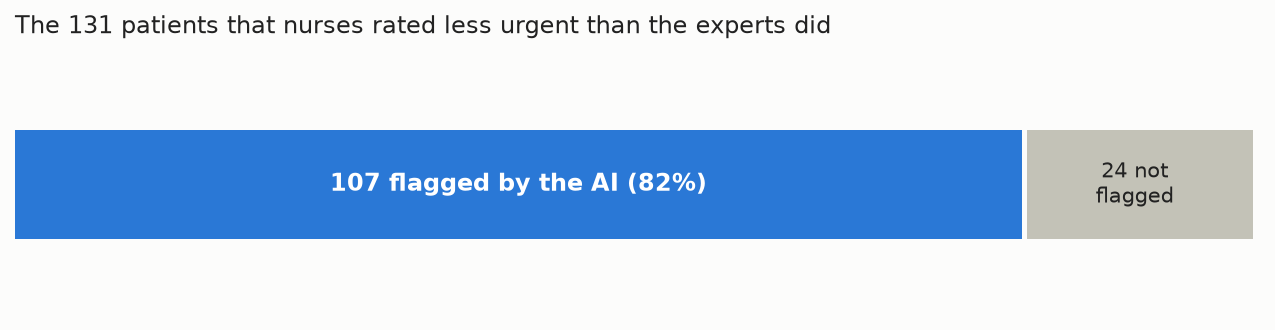

In [9]:
BLUE, GREY, INK, SOFT, SURFACE = ('#2a78d6', '#c3c2b7', '#222222', '#555555', '#fcfcfb')

def tidy(ax):
    ax.set_facecolor(SURFACE)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#bbbbbb")
    ax.tick_params(length=0, colors=SOFT)
    ax.set_axisbelow(True)

def second_check_chart(caught, missed):
    """Of the patients nurses rated too low, how many the AI flags."""
    total = caught + missed
    fig, ax = plt.subplots(figsize=(8.6, 2.3), facecolor=SURFACE, dpi=150)
    ax.barh([0], [caught], color=BLUE, height=0.5)
    ax.barh([0], [missed], left=[caught + total * 0.004], color=GREY, height=0.5)
    ax.text(caught / 2, 0, f"{caught} flagged by the AI ({caught / total:.0%})", ha="center", va="center",
            color="white", fontsize=11.5, fontweight="bold")
    ax.text(caught + missed / 2, 0, f"{missed} not\nflagged", ha="center", va="center", color=INK, fontsize=10)
    ax.set_xlim(0, total * 1.01)
    ax.set_ylim(-0.6, 0.6)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_title(f"The {total} patients that nurses rated less urgent than the experts did",
                 loc="left", fontsize=11.5, color=INK, pad=10)
    tidy(ax)
    ax.spines["bottom"].set_visible(False)
    fig.tight_layout()
    return fig

second_check_chart(caught, missed)
plt.show()

The AI flags most of the patients nurses rated too low. The price is re-checking roughly a third of all
patients, most of whom were rated correctly. Flagging at random would catch only about a third of the
under-rated patients for the same effort, so the flags carry real information.

### Testing the second check harder

Comparing the flags with random ones is a low bar. Here are two simple rules a department could use with no AI:
- **Vital-sign rule:** count the warning signs any nurse knows (very fast or slow pulse, fast breathing, low blood
  pressure, low oxygen, high fever, not fully alert, severe pain) and re-check those with the most.
- **Least urgent first:** re-check the patients the nurse rated lowest, since they are the ones who can be under-rated.

We also try a second AI model built for this job: it sees the nurse's level as well and learns to predict
"the nurse rated this patient too low".

The fair comparison is by **budget**: if nurses have time to re-check only 10%, 20% or 30% of patients, taking the
highest scores first, what share of the under-rated patients do they reach? Each figure has a 95% range in brackets.

In [10]:
def urgency_gap_score(probabilities, nurse):
    """How strongly the level model disagrees with the nurse: the probability that the
    correct level is MORE urgent than the one the nurse gave."""
    levels = np.array(LEVELS)
    return (probabilities * (levels[None, :] < np.asarray(nurse)[:, None])).sum(axis=1)

def vital_sign_rule(df):
    """The simple rule to beat: count the warning signs any nurse would recognise."""
    signs = pd.DataFrame({
        "fast or slow pulse": (df["HR"] > 110) | (df["HR"] < 50),
        "fast breathing": df["RR"] > 24,
        "low blood pressure": df["SBP"] < 90,
        "low oxygen": df["Saturation"] < 92,
        "high fever": df["BT"] >= 38.5,
        "not fully alert": df["Mental"] > 1,
        "severe pain": df["NRS_pain"] >= 8,
        "unmeasurable vital signs": df["unmeasurable"] == 1,
    })
    return signs.sum(axis=1).values

def make_flag_model():
    """A model built for the second check itself: it sees everything known at the door AND the
    nurse's level, and learns to predict 'the nurse rated this patient too low'."""
    prepare = ColumnTransformer([
        ("numbers", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMBERS),
        ("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORIES + ["KTAS_RN"]),
        ("complaint", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True), TEXT),
    ])
    return Pipeline([("prepare", prepare),
                     ("model", LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced"))])

def flag_model_score(df):
    """Each patient scored by a flag model that never saw them (5-fold cross-validation)."""
    under = (df["KTAS_RN"] > df["KTAS_expert"]).astype(int)
    folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
    return cross_val_predict(make_flag_model(), df, under, cv=folds, method="predict_proba")[:, 1]

def caught_within_budget(score, under, budget, rng=None):
    """If nurses can re-check only `budget` of all patients, taking the highest scores first,
    what share of the under-rated patients do they reach?

    A simple rule gives many patients the same score, so the cut-off can fall inside a group of equals,
    and which of them are re-checked is luck. That group is counted by its share: if 40 of 100 equal
    patients fit in the budget, 40% of the under-rated ones among them count as reached. (Breaking the
    tie with one random draw made the simple rules look up to 6 points better or worse than they are.)"""
    score, under = np.asarray(score, dtype=float), np.asarray(under, dtype=bool)
    take = int(round(budget * len(score)))
    cut = np.sort(score)[::-1][take - 1]                  # the lowest score that still gets a re-check
    surely, maybe = score > cut, score == cut
    share = (take - surely.sum()) / maybe.sum()           # of the group at the cut-off, the part that fits
    return (under[surely].sum() + share * under[maybe].sum()) / under.sum()

def plausible_range(statistic, n, rounds=1000):
    """95% range from re-drawing the patients with replacement (bootstrap)."""
    rng = np.random.default_rng(SEED)
    values = [statistic(rng.integers(0, n, n)) for _ in range(rounds)]
    return np.percentile(values, [2.5, 97.5])

scores = {
    "Vital-sign rule (simple baseline)": vital_sign_rule(df),
    "Least urgent first (simple baseline)": nurse.astype(float),
    "AI level model vs nurse": urgency_gap_score(probabilities, nurse),
    "AI flag model (sees nurse level)": flag_model_score(df),
}
budgets = [0.10, 0.20, 0.30]
table = {"Random choice": {f"re-check {b:.0%}": f"{b:.0%}" for b in budgets}}
for name, score in scores.items():
    table[name] = {}
    for b in budgets:
        value = caught_within_budget(score, under, b)
        low, high = plausible_range(lambda pick: caught_within_budget(score[pick], under[pick], b), n)
        table[name][f"re-check {b:.0%}"] = f"{value:.0%} ({low:.0%}-{high:.0%})"
pd.DataFrame(table).T

,re-check 10%,re-check 20%,re-check 30%
Random choice,10%,20%,30%
Vital-sign rule (simple baseline),20% (15%-25%),34% (28%-41%),43% (37%-49%)
Least urgent first (simple baseline),23% (17%-28%),36% (31%-41%),49% (44%-55%)
AI level model vs nurse,37% (30%-45%),67% (60%-75%),77% (70%-83%)
AI flag model (sees nurse level),33% (27%-42%),63% (55%-71%),75% (67%-82%)


In [11]:
low, high = plausible_range(lambda pick: (flag[pick] & under[pick]).sum() / under[pick].sum(), n)
print(f"The safety-first flag from above reaches {caught / under.sum():.0%} of under-rated patients "
      f"(95% range {low:.0%}-{high:.0%}) by re-checking {flag.mean():.0%} of all patients.")

The safety-first flag from above reaches 82% of under-rated patients (95% range 75%-88%) by re-checking 36% of all patients.


### A stricter flag with fewer false alarms

The safety-first flag is right for only about 1 flag in 4, because the safety-first level rates high on purpose.
A stricter rule needs no tuning: flag only when the model thinks it **more likely than not** that the right level
is more urgent than the nurse's. The digital hospital shows this as the strong flag, and the rest of the
safety-first flags as a milder note.

In [12]:
strong = urgency_gap_score(probabilities, nurse) >= 0.50      # "more likely than not": no number was tuned
low, high = plausible_range(lambda pick: (strong[pick] & under[pick]).sum() / under[pick].sum(), n)
print(f"Strong flag: raised for {strong.sum()} patients ({strong.mean():.0%}), reaches {(strong & under).sum()} of "
      f"{under.sum()} under-rated patients ({(strong & under).sum() / under.sum():.0%}, 95% range {low:.0%}-{high:.0%}).")
print(f"Share of flags that are right: strong {(strong & under).sum() / strong.sum():.0%}, "
      f"safety-first {(flag & under).sum() / flag.sum():.0%}.")
print(f"Every strong flag is also a safety-first flag: {bool((strong <= flag).all())}. "
      f"The other {(flag & ~strong).sum()} are shown as a milder note.")

Strong flag: raised for 260 patients (21%), reaches 91 of 131 under-rated patients (69%, 95% range 62%-77%).
Share of flags that are right: strong 35%, safety-first 23%.
Every strong flag is also a safety-first flag: True. The other 201 are shown as a milder note.


### When can a nurse accept the AI's report after a quick look?

In the digital hospital the nurse reviews the AI's report and either accepts it or checks the patient herself.
Accepting is only reasonable where the AI's level holds up. We tried one plain rule: the model is at least 80%
sure, it suggests level 3 to 5, and the patient shows no warning sign. For everyone else the app advises a
personal check.

In [13]:
ai_level = most_likely(probabilities)
quick = (probabilities.max(axis=1) >= 0.80) & (ai_level >= 3) & (vital_sign_rule(df) == 0)
for name, pick in (("Quick review offered", quick), ("Personal check advised", ~quick)):
    print(f"{name:24} {pick.sum():4d} patients ({pick.mean():.0%}):  AI right {np.mean(ai_level[pick] == truth[pick]):.0%}, "
          f"too low {np.mean(ai_level[pick] > truth[pick]):.0%}   |   nurses right {np.mean(nurse[pick] == truth[pick]):.0%}, "
          f"too low {np.mean(nurse[pick] > truth[pick]):.0%}")
urgent = truth <= 2
print(f"Of the {urgent.sum()} patients experts rated level 1 or 2, {int((quick & urgent).sum())} would be offered a quick review.")

Quick review offered      325 patients (26%):  AI right 84%, too low 7%   |   nurses right 89%, too low 7%
Personal check advised    942 patients (74%):  AI right 63%, too low 19%   |   nurses right 84%, too low 11%
Of the 246 patients experts rated level 1 or 2, 10 would be offered a quick review.


Where a quick review is offered (about 1 patient in 4), the AI's level is too low as rarely as the nurses' own.
It is still right less often than the nurses, and a few urgent patients fall inside the group, so the nurse's
review is a real step and not a formality. Everywhere else the AI is clearly worse than a nurse, which is why the
app advises a personal check there. We have not tested this with nurses: accepting a report they have just read
may make them agree with it more often than they should.

The AI reaches clearly more under-rated patients than either simple rule at every budget (about twice as many as the
vital-sign rule), and its ranges do not overlap with theirs. The model built specially for the job did **not** do better than the plain level
model, so we kept the simpler one.

## 8. When the AI says "not sure"

The model's highest probability is its confidence. If it only speaks when confident, it covers fewer patients
but is right more often.

In [14]:
confidence = probabilities.max(axis=1)
rows = {}
for cut in [0.0, 0.5, 0.6, 0.7, 0.8]:
    keep = confidence >= cut
    s = summary(truth[keep], plain[keep])
    rows[f"confident at {cut:.0%} or more"] = {"share of patients handled": f"{keep.mean():.0%}",
                                              "exact level": f"{s['exact']:.0%}", "rated too low": f"{s['under']:.0%}"}
pd.DataFrame(rows).T

,share of patients handled,exact level,rated too low
confident at 0% or more,100%,68%,16%
confident at 50% or more,87%,72%,15%
confident at 60% or more,69%,75%,13%
confident at 70% or more,53%,79%,11%
confident at 80% or more,36%,82%,8%


Even on the cases it is most sure about, the model does not reach the nurses' 85%.

## 9. What does this mean for waiting time? (a simulation)

**This section is a simulation, not a measurement.** The data has no arrival times, so we invent them:
patients arrive at random, three doctors work, and a visit takes 20 minutes on average in a busy department.
The same patients go through the queue four times; only the order in which waiting patients are called changes.
We repeat it 200 times and average.

In [15]:
def simulate_wait(priority, truth, rng, doctors=3, service_minutes=20.0, load=0.95):
    """Average minutes until first seen, for the truly urgent (expert level 1-2) and for everyone.

    This is a SIMULATION. The data has no arrival times, so we invent them: patients arrive at
    random, and each visit takes a random time averaging `service_minutes`. Only the ORDER in
    which waiting patients are called differs between runs.
    """
    n = len(truth)
    order = rng.permutation(n)
    gaps = rng.exponential(service_minutes / (doctors * load), n)
    arrivals = np.cumsum(gaps)
    service = rng.exponential(service_minutes, n)
    free_at = [0.0] * doctors
    heapq.heapify(free_at)
    waiting, waits, i = [], np.zeros(n), 0
    clock = 0.0
    while i < n or waiting:
        doctor_free = heapq.heappop(free_at)
        clock = max(clock, doctor_free)
        if not waiting and i < n and arrivals[i] > clock:
            clock = arrivals[i]
        while i < n and arrivals[i] <= clock:
            patient = order[i]
            heapq.heappush(waiting, (priority[patient], arrivals[i], patient, i))
            i += 1
        _, arrived, patient, k = heapq.heappop(waiting)
        waits[patient] = clock - arrived
        heapq.heappush(free_at, clock + service[k])
    urgent = np.asarray(truth) <= 2
    return waits[urgent].mean(), waits.mean()

def compare_queues(df, ai_levels, rounds=200):
    rng = np.random.default_rng(SEED)
    truth = df["KTAS_expert"].values
    orderings = {
        "First come, first served": np.zeros(len(df)),
        "Nurse levels": df["KTAS_RN"].values,
        "AI levels (safety-first)": ai_levels,
        "Expert levels (the ideal)": truth,
    }
    rows = {}
    for name, priority in orderings.items():
        results = np.array([simulate_wait(priority, truth, np.random.default_rng(rng.integers(1 << 31)))
                            for _ in range(rounds)])
        rows[name] = results.mean(axis=0)
    return rows

queues = compare_queues(df, safe)
pd.DataFrame({name: {"urgent patients (level 1-2) wait": f"{u:.0f} min", "everyone waits": f"{a:.0f} min"}
              for name, (u, a) in queues.items()}).T

,urgent patients (level 1-2) wait,everyone waits
"First come, first served",88 min,88 min
Nurse levels,13 min,90 min
AI levels (safety-first),24 min,90 min
Expert levels (the ideal),7 min,87 min


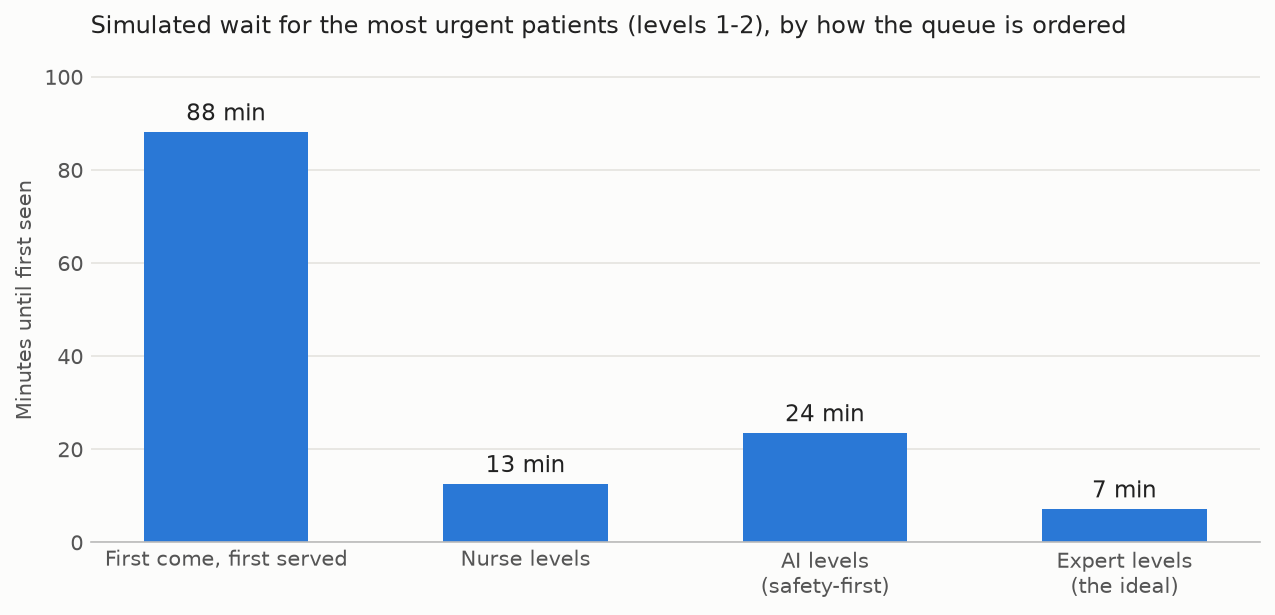

In [16]:
def wait_chart(rows):
    """rows: {queue order: (minutes urgent patients wait, minutes everyone waits)}"""
    names = [n.replace(" (", "\n(") for n in rows]
    minutes = [v[0] for v in rows.values()]
    fig, ax = plt.subplots(figsize=(8.6, 4.2), facecolor=SURFACE, dpi=150)
    bars = ax.bar(names, minutes, width=0.55, color=BLUE)
    ax.bar_label(bars, fmt="%.0f min", padding=3, fontsize=11, color=INK)
    ax.set_ylim(0, max(minutes) * 1.18)
    ax.set_ylabel("Minutes until first seen", color=SOFT)
    ax.set_title("Simulated wait for the most urgent patients (levels 1-2), by how the queue is ordered",
                 loc="left", fontsize=11.5, color=INK, pad=12)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    tidy(ax)
    fig.tight_layout()
    return fig

wait_chart(queues)
plt.show()

Any urgency ordering cuts the wait for the most urgent patients enormously compared with first come, first
served. The AI's ordering is better than none and worse than a nurse's. Average waiting time for everyone
stays the same: a priority queue moves waiting from urgent patients to minor ones, it does not remove it.

## 10. Does it work equally well for everyone?

In [17]:
groups = {"Women": df["Sex"] == 1, "Men": df["Sex"] == 2, "Under 65": df["Age"] < 65, "65 and over": df["Age"] >= 65}
pd.DataFrame({name: {"patients": int(mask.sum()),
                     "AI safety-first: rated too low": f"{(safe[mask.values] > truth[mask.values]).mean():.0%}",
                     "Nurses: rated too low": f"{(nurse[mask.values] > truth[mask.values]).mean():.0%}"}
              for name, mask in groups.items()}).T

,patients,AI safety-first: rated too low,Nurses: rated too low
Women,606,9%,12%
Men,661,7%,9%
Under 65,805,8%,10%
65 and over,462,8%,12%


## 11. Does it survive a move to another hospital?

Train on one hospital only, test on the other. The last two rows show the same patients scored by the model
from section 4 (trained on both hospitals), for comparison.

In [18]:
rows = {}
for train_group, test_group in [(1, 2), (2, 1)]:
    train, test = df[df["Group"] == train_group], df[df["Group"] == test_group]
    model = make_model().fit(train, train["KTAS_expert"])
    p = np.zeros((len(test), 5))
    p[:, [LEVELS.index(c) for c in model.classes_]] = model.predict_proba(test)
    rows[f"Trained at hospital {train_group}, tested at hospital {test_group}"] = (test["KTAS_expert"].values, most_likely(p))
for group in [1, 2]:
    mask = (df["Group"] == group).values
    rows[f"Trained on both, hospital {group} patients"] = (truth[mask], plain[mask])
results_table(rows)

,patients,exact level,rated too low,rated too high,level 1-2 sent to slow queue
"Trained at hospital 1, tested at hospital 2",579,55%,174 (30%),85 (15%),49
"Trained at hospital 2, tested at hospital 1",688,58%,132 (19%),156 (23%),12
"Trained on both, hospital 1 patients",688,67%,106 (15%),119 (17%),9
"Trained on both, hospital 2 patients",579,69%,94 (16%),85 (15%),10


Accuracy drops when the model moves to a hospital it was not trained at, and more urgent patients end up in the
slow queue. A triage model would need testing at each hospital before use there.

## 12. Where it fails

Patients the experts rated level 1 or 2 whom the safety-first model put at level 4 or 5.

In [19]:
bad = df[(truth <= 2) & (safe >= 4)].assign(AI_level=safe[(truth <= 2) & (safe >= 4)])
print(f"{len(bad)} urgent patients sent to the slow queue by the AI")
bad[[TEXT, "Age", "Mental", "NRS_pain", "SBP", "HR", "RR", "BT", "Saturation", "KTAS_RN", "KTAS_expert", "AI_level"]]

7 urgent patients sent to the slow queue by the AI


,Chief_complain,Age,Mental,NRS_pain,SBP,HR,RR,BT,Saturation,KTAS_RN,KTAS_expert,AI_level
58,fever,59.0,1,3.0,156.0,126.0,22.0,38.0,NaN,3,2,4
180,"erection, penile",42.7,1,0.0,NaN,NaN,NaN,NaN,NaN,5,2,5
190,흉통,78.0,1,2.0,NaN,NaN,16.0,35.9,NaN,2,2,4
407,general weakness,72.4,1,3.0,140.0,51.0,20.0,36.0,100.0,2,2,4
469,nausea,24.3,1,4.0,120.0,80.0,20.0,36.0,98.0,2,2,4
839,"di, drug intoxication",21.0,2,0.0,113.0,87.0,18.0,36.9,NaN,2,2,4
1001,eye trauma,57.0,1,0.0,157.0,82.0,20.0,36.0,NaN,2,2,4


Six of the seven have a reason we can point to, and the seventh is a rare complaint the model had hardly seen:
- one complaint is written in Korean ("chest pain") and the vital signs are missing, so the model had almost nothing to go on;
- two are poisonings and one is an eye injury, where the danger does not show in the vital signs;
- one patient has a slow pulse (51) and one a fast pulse with fever, which the model under-weighted;
- nurses rated five of these seven patients correctly, which is a reminder that the model lacks what a nurse sees and hears.

## 13. Sending the patient to the right department

A level says how soon a patient must be seen. It does not say by whom. Here we train a second model to suggest
the department.

**The answer key.** Every patient in the data has a final diagnosis made in the emergency department. We matched
each of the 584 distinct diagnoses to one of nine departments. The table is `data/diagnosis_departments.csv`,
built by `assignment.py`: word rules matched 487 diagnoses, we corrected 14 by hand after reading every row, and
83 rarer ones matched no rule and count as general medicine. The table is our own work and has not been reviewed
by a clinician.

In [20]:
table_file = "data/diagnosis_departments.csv"
if not os.path.exists(table_file):
    table_file = "https://raw.githubusercontent.com/potlatiy/emergency-triage-ai/main/data/diagnosis_departments.csv"
table = pd.read_csv(table_file, keep_default_na=False)
department = df["Diagnosis in ED"].fillna("").str.strip().map(dict(zip(table["diagnosis"], table["department"]))).fillna("General medicine")
department.value_counts().to_frame("patients")

,patients
Diagnosis in ED,
Gastroenterology and surgery,268
Trauma and orthopaedics,211
Neurology,195
General medicine,161
Cardiology,141
"Eye, ear, nose and throat",108
Urology and kidney,85
Respiratory medicine,68
Obstetrics and gynaecology,30


**The simple rule to beat.** Pick the department from key words in the complaint: "chest" means cardiology,
"abd" means gastroenterology, and so on. This is what our digital hospital used before the model existed.

In [21]:
import re
DEPARTMENTS = [
    ("Obstetrics and gynaecology", r"vagin|pregnan|menstr|period pain|pelvic|labou?r pain|miscarr"),
    ("Urology and kidney", r"urin|flank|kidney|dysuria|hematuria|testic|scrot|voiding|pee|bladder"),
    ("Cardiology", r"chest|palpitat|heart|흉통"),
    ("Respiratory medicine", r"dyspnea|breath|cough|asthma|sputum|hemoptysis|wheez"),
    ("Neurology", r"headache|dizz|vertigo|weakness|mental|seizure|syncope|numb|dysarthria|faint|stroke|confus"),
    ("Trauma and orthopaedics", r"wound|fractur|lacerat|burn|injur|sprain|trauma|bite|fall|fell|broke|twist|cut |bleed|"
                                r"ankle|knee|wrist|shoulder|arm |leg |back pain|hip|finger|foot|hand "),
    ("Gastroenterology and surgery", r"abd|epigastr|stomach|belly|bowel|vomit|diarrh|nausea|melena|hemateme|stool|"
                                     r"constipat|ruq|rlq"),
    ("Eye, ear, nose and throat", r"eye|ocular|visual|vision|ear |throat|nose|epistaxis|foreign body"),
]

def keyword_rule(complaint, injury):
    text = f" {complaint} "
    for name, pattern in DEPARTMENTS:
        if re.search(pattern, text):
            return name
    return "Trauma and orthopaedics" if injury else "General medicine"

rule_guess = np.array([keyword_rule(c, i == 2) for c, i in zip(df[TEXT], df["Injury"])])

**The model.** The same inputs and preparation as the urgency model, predicting a department instead of a level.
As before, every patient is predicted by a model that never saw them.

In [22]:
department_model = Pipeline([("prepare", make_model().named_steps["prepare"]),
                             ("model", LogisticRegression(max_iter=3000, C=3.0))])
folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
odds = cross_val_predict(department_model, df, department, cv=folds, method="predict_proba")
names = np.array(sorted(department.unique()))
ranked = names[np.argsort(-odds, axis=1)]          # every department, best guess first
model_guess, sureness = ranked[:, 0], odds.max(axis=1)
answer = department.values

def share_right(guess):
    right = guess == answer
    rng = np.random.default_rng(SEED)
    draws = [right[rng.integers(0, n, n)].mean() for _ in range(1000)]
    low, high = np.percentile(draws, [2.5, 97.5])
    return f"{right.mean():.0%} ({low:.0%}-{high:.0%})"

most_common = department.mode()[0]
mixed = np.where(sureness >= 0.70, model_guess, rule_guess)
pd.DataFrame({"picks the right department": {
    f"Baseline: always {most_common.lower()}": share_right(np.full(n, most_common)),
    "Key-word rule on the complaint": share_right(rule_guess),
    "Trained model": share_right(model_guess),
    "Model when at least 70% sure, key-word rule otherwise": share_right(mixed),
}})

,picks the right department
Baseline: always gastroenterology and surgery,21% (19%-23%)
Key-word rule on the complaint,67% (64%-69%)
Trained model,70% (68%-73%)
"Model when at least 70% sure, key-word rule otherwise",69% (66%-71%)


In [23]:
rng = np.random.default_rng(SEED)
model_right, rule_right = model_guess == answer, rule_guess == answer
gaps = []
for _ in range(1000):
    pick = rng.integers(0, n, n)
    gaps.append(model_right[pick].mean() - rule_right[pick].mean())
low, high = np.percentile(gaps, [2.5, 97.5])
print(f"Model minus key-word rule: {model_right.mean() - rule_right.mean():+.1%} (95% range {low:+.1%} to {high:+.1%})")
for k in [1, 2, 3]:
    hit = np.mean([answer[i] in ranked[i, :k] for i in range(n)])
    print(f"The right department is among the model's top {k}: {hit:.0%}")

Model minus key-word rule: +3.7% (95% range +1.4% to +6.1%)
The right department is among the model's top 1: 70%
The right department is among the model's top 2: 82%
The right department is among the model's top 3: 88%


In [24]:
pd.DataFrame({name: {"patients": int((answer == name).sum()),
                     "trained model": f"{(model_guess[answer == name] == name).mean():.0%}",
                     "key-word rule": f"{(rule_guess[answer == name] == name).mean():.0%}"}
              for name in names}).T

,patients,trained model,key-word rule
Cardiology,141,77%,66%
"Eye, ear, nose and throat",108,52%,46%
Gastroenterology and surgery,268,81%,75%
General medicine,161,47%,52%
Neurology,195,83%,73%
Obstetrics and gynaecology,30,50%,53%
Respiratory medicine,68,54%,65%
Trauma and orthopaedics,211,84%,82%
Urology and kidney,85,47%,44%


The model beats the key-word rule by a few points, and the gap is larger than chance alone would give. It is
weaker than the rule for respiratory, gynaecology and general medicine patients.

### Why not 90%?

We tried eleven versions of this model (different settings, whole words as well as letter patterns, a support
vector machine, a random forest, gradient boosting). All landed between 67% and 71%. The next cell shows why:
the same complaint leads to different departments.

In [25]:
wording = df[TEXT]
shared = wording.map(wording.value_counts()) >= 2
usual = department[shared].groupby(wording[shared]).transform(lambda group: group.mode()[0])
print(f"{shared.mean():.0%} of patients share their exact complaint wording with another patient.")
print(f"Even knowing the most common department for that exact wording is right only {(department[shared] == usual).mean():.0%} of the time.")
pd.DataFrame({w: department[wording == w].value_counts().head(4) for w in ["dyspnea", "fever", "dizziness"]}).fillna(0).astype(int)

79% of patients share their exact complaint wording with another patient.
Even knowing the most common department for that exact wording is right only 77% of the time.


,dyspnea,fever,dizziness
Diagnosis in ED,,,
Cardiology,15,0,6
"Eye, ear, nose and throat",0,0,13
Gastroenterology and surgery,3,9,0
General medicine,8,23,4
Neurology,0,0,33
Respiratory medicine,31,5,0
Urology and kidney,0,6,0


In [26]:
memorised = Pipeline([("prepare", make_model().named_steps["prepare"]),
                      ("model", LogisticRegression(max_iter=3000, C=3.0))]).fit(df, department)
print(f"NOT a result: scored on the very patients it trained on, the same model gets {(memorised.predict(df) == answer).mean():.0%}.")

NOT a result: scored on the very patients it trained on, the same model gets 83%.

A patient with "dyspnea" may have a lung problem, a heart problem or something else, so the words at the door do
not fully decide the department. A score of 90% or more is only reachable by testing a model on the patients it
trained on, as the last cell shows. That is memorising, and it says nothing about new patients.

**What we do with this.** The right department is among the model's top three far more often than it is the top
one, so the digital hospital shows the nurse three suggestions and she chooses. And because the model learned
from complaints written by nurses, it decides by itself only when it is at least 70% sure; the key-word rule
decides otherwise.

## 14. A range of levels with a promise

One level is right for about two patients in three. A nurse may be better served by an honest range: "level 3 or 4".

We make the range like this. For every patient, look at the probability the model gave to the level the experts
chose. Sort those probabilities and put a **cut** just low enough that 90% of the patients keep the experts' level.
A new patient's range is then every level whose probability reaches the cut (plus the most likely level, and any
level in between, so the range has no holes). This is called *conformal prediction*. Nothing is tuned by hand: the
only choice is the promise, 90%.

**The fair test.** The cut is found on one random half of the patients and tried on the other half, 500 times.
Every probability already comes from a model that never saw the patient.

In [27]:
def range_cut(probabilities, truth, coverage=0.90):
    given = np.sort(probabilities[np.arange(len(truth)), np.asarray(truth) - 1])       # what the right level got
    may_miss = int(np.floor((len(given) + 1) * (1 - coverage)))                        # how many the promise lets us miss
    return float(given[may_miss - 1]) if may_miss else 0.0

def level_range(probabilities, cut):
    keep = probabilities >= cut
    keep[np.arange(len(probabilities)), probabilities.argmax(axis=1)] = True           # the most likely level is always in
    return keep.argmax(axis=1) + 1, 5 - keep[:, ::-1].argmax(axis=1)                   # most urgent, least urgent

def range_figures(coverage, rounds=500):
    rng, rows = np.random.default_rng(SEED), []
    for _ in range(rounds):
        order = rng.permutation(n)
        first, second = order[: n // 2], order[n // 2:]
        low, high = level_range(probabilities[second], range_cut(probabilities[first], truth[first], coverage))
        t = truth[second]
        inside = (low <= t) & (t <= high)
        rows.append([inside.mean(), (high - low + 1).mean(), (high == low).mean(), inside[t <= 2].mean(),
                     (t < low).mean(), (t > high).mean()] + [inside[t == level].mean() for level in LEVELS])
    return np.array(rows)

table = {}
for coverage in (0.90, 0.95):
    rows = range_figures(coverage)
    m = rows.mean(axis=0)
    table[f"range, promise {coverage:.0%}"] = {
        "experts' level inside": f"{m[0]:.1%}", "over the 500 tries": f"{np.percentile(rows[:, 0], 2.5):.0%} to {np.percentile(rows[:, 0], 97.5):.0%}",
        "levels wide": f"{m[1]:.1f}", "a single level": f"{m[2]:.0%}", "urgent patients (1-2) inside": f"{m[3]:.0%}",
        "patient more urgent than the range": f"{m[4]:.1%}", "less urgent": f"{m[5]:.1%}",
        "inside, by expert level 1 to 5": ", ".join(f"{share:.0%}" for share in m[6:])}
likely = probabilities.argmax(axis=1) + 1
low, high = np.maximum(likely - 1, 1), np.minimum(likely + 1, 5)
inside = (low <= truth) & (truth <= high)
table["baseline: most likely level, one either side"] = {
    "experts' level inside": f"{inside.mean():.1%}", "over the 500 tries": "", "levels wide": f"{(high - low + 1).mean():.1f}",
    "a single level": "0%", "urgent patients (1-2) inside": f"{inside[truth <= 2].mean():.0%}",
    "patient more urgent than the range": f"{(truth < low).mean():.1%}", "less urgent": f"{(truth > high).mean():.1%}",
    "inside, by expert level 1 to 5": ", ".join(f"{inside[truth == level].mean():.0%}" for level in LEVELS)}
pd.DataFrame(table).T

,experts' level inside,over the 500 tries,levels wide,a single level,urgent patients (1-2) inside,patient more urgent than the range,less urgent,"inside, by expert level 1 to 5"
"range, promise 90%",90.6%,87% to 93%,2.0,27%,80%,4.7%,4.8%,"78%, 80%, 96%, 96%, 58%"
"range, promise 95%",95.4%,93% to 97%,2.5,9%,89%,2.2%,2.3%,"85%, 90%, 98%, 99%, 77%"
"baseline: most likely level, one either side",95.7%,,2.9,0%,92%,1.7%,2.5%,"96%, 91%, 99%, 97%, 79%"


The promise is kept: with a 90% promise the experts' level was inside the range for about 91% of patients the cut
had not seen, and the range is two levels wide on average. At the same coverage as the simple baseline (about 95%)
our range is narrower, 2.5 levels against 2.9.

**The weak spot.** The promise is an average over all patients. It does not hold for every group: only about 8 in 10
of the most urgent patients (levels 1 and 2) are inside the 90% range, and fewer than 6 in 10 of level 5. For the
urgent patients the simple baseline does better (92%). So the range tells a nurse how unsure Meddy is. It is not
a guarantee for one patient, and the digital hospital says so on the screen.

## 15. Patients like this one

A number is hard to trust. So next to its level, Meddy shows the nurse five real patients from the data who look
most like the patient in front of her, with the level their nurse gave and the level the experts gave. The
diagnosis is never used and never shown.

"Alike" mixes three things the urgency model also reads: the words of the complaint (40%), the numbers such as age
and vital signs (40%), and the tick-box answers such as injury and alertness (20%). Patients with the same *kind*
of complaint come first. The kind is what the hospital's key-word rule reads in the complaint, so "it burns when
I pee" finds the patients the data calls "dysuria".

**The fair test.** Each patient is looked up among the patients of the other four folds, so nobody finds
themselves. We then ask: did most of the five have the experts' level? Did at least one?

In [28]:
from scipy import sparse
from sklearn.metrics.pairwise import cosine_similarity

# The hospital's key-word rule as it is today (hospital/core.py). It reads the kind of complaint, never the diagnosis.
KINDS = [
    ("Obstetrics and gynaecology", r"vagin|pregnan|menstr|period pain|pelvic|labou?r pain|miscarr"),
    ("Urology and kidney", r"\burin|flank|kidney|dysuria|hematuria|testic|scrot|\bvoiding|\bpee(s|d|ing)?\b|(?<!gall)bladder"),
    ("Cardiology", r"chest|palpitat|\bheart(?!burn)|흉통"),
    ("Respiratory medicine", r"dyspnea|breath|cough|asthma|sputum|hemoptysis|wheez"),
    ("Neurology", r"headache|dizz|vertigo|weakness|mental|seizure|syncope|\bnumb(ness|ing)?\b|dysarthria|faint|\bstroke|confus|"
                  r"speech|slurr|droop"),
    ("Trauma and orthopaedics", r"wound|fractur|lacerat|\bburn|injur|sprain|trauma|\bbit(e|es|ten)\b|\bfall(s|en)?\b|"
                                r"\bfell\b|\bbroke|twist|\bcuts?\b|bleed|ankle|knee|wrist|shoulder|\b(fore)?arms?\b|"
                                r"\blegs?\b|back pain|\bhips?\b|finger|\bfoot\b|\bfeet\b|\bhands?\b"),
    ("Gastroenterology and surgery", r"abd|epigastr|stomach|belly|bowel|vomit|diarrh|nausea|melena|hemateme|stool|"
                                     r"constipat|ruq|rlq|heartburn|reflux|gall ?bladder"),
    ("Eye, ear, nose and throat", r"\beye|ocular|visual|vision|\bear(s|ache)?\b|throat|\bnose|epistaxis|foreign body"),
]

def kind_of(complaint, injury):
    text = f" {complaint} "
    for name, pattern in KINDS:
        if re.search(pattern, text):
            return name
    return "Trauma and orthopaedics" if injury else None          # None: the rule found no word it knows

kinds = np.array([kind_of(c, i == 2) for c, i in zip(df[TEXT], df["Injury"])], dtype=object)

def three_parts(prepare, patients):
    prepared = sparse.csr_matrix(prepare.transform(patients))
    words = len(prepare.named_transformers_["complaint"].vocabulary_)
    return (prepared[:, :len(NUMBERS)].toarray(), prepared[:, len(NUMBERS):prepared.shape[1] - words].toarray(),
            prepared[:, prepared.shape[1] - words:])

def most_alike(shares, use_kinds=True, k=5):
    """For every patient: the k most similar patients among the other four folds."""
    found = np.zeros((n, k), dtype=int)
    for others, held_out in StratifiedKFold(5, shuffle=True, random_state=SEED).split(df, truth):
        prepare = make_model().named_steps["prepare"].fit(df.iloc[others])          # fitted without the held-out patients
        numbers, answers, words = three_parts(prepare, df.iloc[held_out])
        known_numbers, known_answers, known_words = three_parts(prepare, df.iloc[others])
        gap = ((numbers[:, None, :] - known_numbers[None, :, :]) ** 2).mean(axis=2)
        alike = (shares[0] * cosine_similarity(words, known_words) + shares[1] * np.exp(-gap / 2)
                 + shares[2] * (answers @ known_answers.T) / len(CATEGORIES))
        if use_kinds:                                                               # the same kind of complaint comes first
            for row, kind in enumerate(kinds[held_out]):
                if kind is not None:
                    alike[row] += kinds[others] == kind
        found[held_out] = others[np.argsort(-alike, axis=1, kind="stable")[:, :k]]
    return found

def vote(levels):                                                # the level most of the five had; a tie goes to the more urgent
    return np.stack([(levels == level).sum(axis=1) for level in LEVELS], axis=1).argmax(axis=1) + 1

rows = {}
for name, shares, use_kinds in [("same kind first, then the 40/40/20 mix (used)", (0.4, 0.4, 0.2), True),
                                ("the 40/40/20 mix without the kind", (0.4, 0.4, 0.2), False),
                                ("complaint words only", (1, 0, 0), False), ("numbers only", (0, 1, 0), False)]:
    found = most_alike(shares, use_kinds)
    rows[name] = {"most of the five had the experts' level": f"{(vote(truth[found]) == truth).mean():.0%}",
                  "at least one of the five had it": f"{(truth[found] == truth[:, None]).any(axis=1).mean():.0%}"}
    if use_kinds:
        similar_found = found
rows["for comparison: always the most common level"] = {"most of the five had the experts' level": f"{(truth == np.bincount(truth).argmax()).mean():.0%} right", "at least one of the five had it": ""}
rows["for comparison: the urgency model"] = {"most of the five had the experts' level": f"{(probabilities.argmax(axis=1) + 1 == truth).mean():.0%} right", "at least one of the five had it": ""}
print(f"The key-word rule recognised the complaint of {np.mean([kind is not None for kind in kinds]):.0%} of the patients.")
pd.DataFrame(rows).T

The key-word rule recognised the complaint of 80% of the patients.


,most of the five had the experts' level,at least one of the five had it
"same kind first, then the 40/40/20 mix (used)",61%,89%
the 40/40/20 mix without the kind,60%,89%
complaint words only,52%,89%
numbers only,47%,86%
for comparison: always the most common level,38% right,
for comparison: the urgency model,68% right,


In [29]:
# One example: a patient with chest pain, and the five patients most like them among the other folds.
example = int(np.flatnonzero(df[TEXT] == "pain, chest")[0])
columns = [TEXT, "Age", "Sex", "KTAS_RN", "KTAS_expert"]
print("The patient:", df.loc[example, columns].to_dict())
df.loc[similar_found[example], columns].rename(columns={TEXT: "their complaint", "KTAS_RN": "nurse's level", "KTAS_expert": "experts' level"})

The patient: {'Chief_complain': 'pain, chest', 'Age': 78.0, 'Sex': 2, 'KTAS_RN': 2, 'KTAS_expert': 3}


,their complaint,Age,Sex,nurse's level,experts' level
668,"pain, chest",54.0,2,2,2
393,"pain, chest",68.0,2,2,2
467,"pain, chest",24.0,2,3,3
221,"pain, chest",58.0,1,2,2
403,ant. chest pain,71.5,2,2,2


Most of the five similar patients had the experts' level for about 6 patients in 10, and at least one of them had it
for about 9 in 10. That is better than always guessing the most common level and **weaker than the urgency model**.
So the similar patients are shown as evidence to look at, not as a second opinion.

Two limits. We tried four ways of measuring "alike" and kept the best on these same folds, so the 6 in 10 is a
little flattering. And the patients in the data describe their complaint in two or three clinical words; a
complaint the key-word rule does not recognise finds patients who are alike in age and measurements only, and the
screen says so.

## 16. The demo function

Trained on all 1,267 patients, since it is for demonstration and not for scoring.

In [30]:
final_model = make_model().fit(df, truth)

def suggest(complaint, age, sex, arrival, injury, mental, pain, sbp, dbp, hr, rr, temp, oxygen=None, nurse_level=None):
    patient = pd.DataFrame([{TEXT: complaint.lower(), "Age": age, "Sex": sex, "Arrival mode": arrival,
                             "Injury": injury, "Mental": mental, "Pain": int(pain > 0), "NRS_pain": pain,
                             "Patients number per hour": df["Patients number per hour"].median(),
                             "SBP": sbp, "DBP": dbp, "HR": hr, "RR": rr, "BT": temp,
                             "Saturation": np.nan if oxygen is None else oxygen, "unmeasurable": 0}])
    p = final_model.predict_proba(patient)
    level = int(safety_first(p)[0])
    text = f"Suggested level {level} (safety-first). Probabilities: " + ", ".join(
        f"L{l} {q:.0%}" for l, q in zip(LEVELS, p[0]))
    if nurse_level is not None and level < nurse_level:
        text += f"\nFLAG: more urgent than the nurse's level {nurse_level}. Please re-check."
    return text

print(suggest("ant. chest pain", 67, 2, 2, 1, 1, 6, 95, 60, 118, 26, 36.8, 91, nurse_level=3))
print(suggest("ankle pain", 24, 1, 1, 2, 1, 3, 122, 78, 76, 16, 36.5, 99, nurse_level=4))

Suggested level 2 (safety-first). Probabilities: L1 0%, L2 97%, L3 2%, L4 0%, L5 0%
FLAG: more urgent than the nurse's level 3. Please re-check.
Suggested level 4 (safety-first). Probabilities: L1 0%, L2 1%, L3 1%, L4 81%, L5 18%


## 17. What we found

1. **The model cannot replace a triage nurse.** It gives the exact level far more often than the baseline and
   clearly less often than nurses.
2. **It is useful as a second check.** It flags most of the patients nurses rated too low, at the price of
   re-checking about a third of all patients.
3. **Ordering the queue by urgency matters more than who does the ordering.** In our simulation any urgency
   ordering cuts the wait of the most urgent patients several times over.
4. **It does not travel well.** Trained at one hospital and used at the other, it gets worse.
5. **A second model can suggest the department, modestly better than key words.** The complaint alone does not
   fully decide the department, so the model offers three suggestions and the nurse chooses.
6. **A range of levels keeps its promise on average, not for every group.** The experts' level is inside the range
   for 9 patients in 10, but only for 8 in 10 of the most urgent patients.
7. **Similar past patients are evidence, not a second opinion.** Most of the five had the experts' level for 6
   patients in 10, which is weaker than the model.

## Limits

- 1,267 patients from one country, and only 26 at level 1.
- The waiting times are simulated with invented arrivals, doctors and visit lengths.
- The safety weighting (3 to 1) is our choice. A hospital would set it with its own staff.
- The "correct" levels come from experts reviewing records afterwards; they are a judgement too.
- The department answer key is our own diagnosis-to-department table and has not been reviewed by a clinician.
- The second-check idea assumes a nurse re-checks a flagged patient and corrects the level. We did not test that
  with real nurses.

This project is a prototype and is not medical advice.